# CNN Classifier on MNIST


## 1. Kaggle environment and reproducibility


In [1]:
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import platform
import random
import struct
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), 'Enable a GPU in Kaggle before continuing.'
device = torch.device('cuda:0')
RESULTS_DIR = Path('/kaggle/working/results')
PLOTS_DIR = Path('/kaggle/working/plots')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

environment = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(device),
    'cuda_runtime': torch.version.cuda,
    'seed': SEED,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
print(json.dumps(environment, indent=2))
(RESULTS_DIR / 'mnist_environment.json').write_text(json.dumps(environment, indent=2))


{
  "python": "3.13.15",
  "gpu": "Tesla T4",
  "cuda_runtime": "12.8",
  "seed": 42,
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0"
  }
}


272

### GPU smoke check


In [2]:
smoke_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
smoke_x = torch.rand(8, 1, 28, 28, device=device)
smoke_y = torch.arange(8, device=device)
smoke_loss = nn.CrossEntropyLoss()(smoke_model(smoke_x), smoke_y)
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in smoke_model.parameters())
print('PASS: GPU forward pass, cross-entropy, and finite gradients.')
del smoke_model, smoke_x, smoke_y, smoke_loss
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


PASS: GPU forward pass, cross-entropy, and finite gradients.


## 2. Locate and validate MNIST


In [3]:
INPUT_DIR = Path('/kaggle/input')
file_names = {
    'train_images': 'train-images-idx3-ubyte',
    'train_labels': 'train-labels-idx1-ubyte',
    'test_images': 't10k-images-idx3-ubyte',
    'test_labels': 't10k-labels-idx1-ubyte',
}

def read_bytes(path):
    return gzip.decompress(path.read_bytes()) if path.suffix == '.gz' else path.read_bytes()

source_paths = {}
source_hashes = {}
for key, name in file_names.items():
    alternatives = {name, name.replace('-idx', '.idx')}
    accepted_names = alternatives | {n + '.gz' for n in alternatives}
    matches = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.name in accepted_names)
    assert matches, f'Missing {name}. Attach the MNIST dataset specified in the lab.'
    hashes = {hashlib.sha256(read_bytes(p)).hexdigest() for p in matches}
    assert len(hashes) == 1, f'Conflicting copies of {name}: {matches}'
    source_paths[key] = matches[0]
    source_hashes[key] = hashes.pop()
    print(f'{key}: {matches[0]} ({len(matches)} matching copies)')

def read_idx(path):
    raw = read_bytes(path)
    assert len(raw) >= 8, f'Incomplete IDX header: {path}'
    magic, count = struct.unpack('>II', raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack('>II', raw[8:16])
        assert (rows, cols) == (28, 28)
        assert len(raw) == 16 + count * rows * cols
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    assert magic == 2049, f'Unexpected IDX magic number: {magic}'
    assert len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

official_train_images = read_idx(source_paths['train_images'])
official_train_labels = read_idx(source_paths['train_labels'])
official_test_images = read_idx(source_paths['test_images'])
official_test_labels = read_idx(source_paths['test_labels'])
assert official_train_images.shape == (60000, 28, 28)
assert official_test_images.shape == (10000, 28, 28)
assert official_train_labels.shape == (60000,)
assert official_test_labels.shape == (10000,)
for labels in (official_train_labels, official_test_labels):
    assert np.array_equal(np.unique(labels), np.arange(10))
print('Official training images:', official_train_images.shape)
print('Official test images:', official_test_images.shape)
print('Pixel dtype:', official_train_images.dtype)
print('Training pixel range:', official_train_images.min(), official_train_images.max())
print('PASS: IDX sizes, image dimensions, and label ranges.')


train_images: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte (2 matching copies)
train_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte (2 matching copies)
test_images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (2 matching copies)
test_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (2 matching copies)
Official training images: (60000, 28, 28)
Official test images: (10000, 28, 28)
Pixel dtype: uint8
Training pixel range: 0 255
PASS: IDX sizes, image dimensions, and label ranges.


## 3. Shared train, validation, and test partitions


In [4]:
train_indices, validation_indices = train_test_split(
    np.arange(len(official_train_labels)),
    test_size=6000,
    random_state=SEED,
    stratify=official_train_labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
test_indices = np.arange(len(official_test_labels))
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(60000))

split_manifest = pd.concat([
    pd.DataFrame({'split': 'train', 'source': 'official_train', 'source_index': train_indices}),
    pd.DataFrame({'split': 'validation', 'source': 'official_train', 'source_index': validation_indices}),
    pd.DataFrame({'split': 'test', 'source': 'official_test', 'source_index': test_indices}),
], ignore_index=True)
assert not split_manifest.duplicated(['source', 'source_index']).any()
manifest_text = split_manifest.to_csv(index=False, lineterminator='\n')
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
(RESULTS_DIR / 'mnist_split_manifest.csv').write_text(manifest_text)

split_labels = {
    'train': official_train_labels[train_indices],
    'validation': official_train_labels[validation_indices],
    'test': official_test_labels,
}
class_counts = pd.DataFrame({name: np.bincount(labels, minlength=10) for name, labels in split_labels.items()})
class_counts.index.name = 'digit'
assert (class_counts > 0).all().all()
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'mnist_split_class_counts.csv')
print('Partition sizes:', {name: len(labels) for name, labels in split_labels.items()})
print('Split SHA256:', split_hash)
print('PASS: disjoint source indices, full coverage, and all ten classes in each partition.')


,train,validation,test
digit,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


Partition sizes: {'train': 54000, 'validation': 6000, 'test': 10000}
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: disjoint source indices, full coverage, and all ten classes in each partition.


### Training examples and class distribution


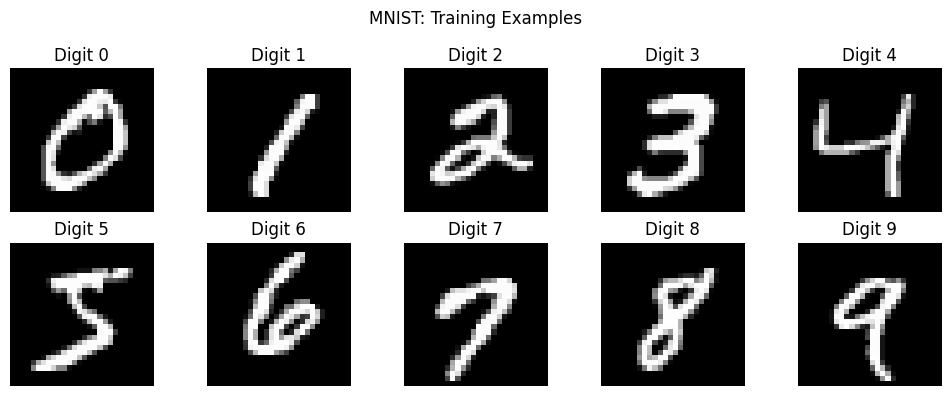

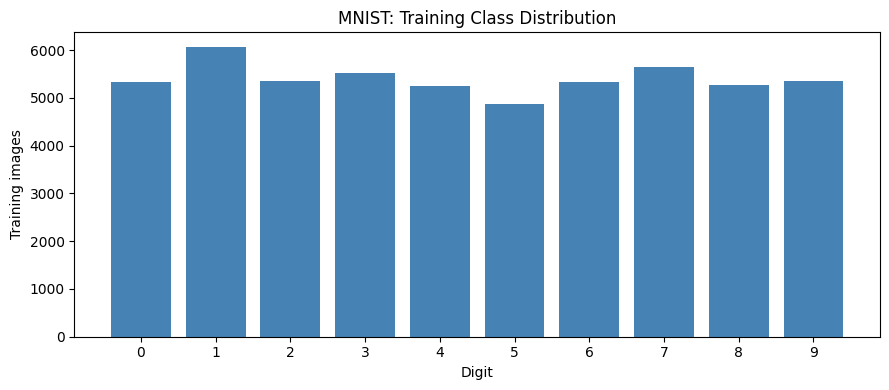

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = train_indices[np.flatnonzero(official_train_labels[train_indices] == digit)[0]]
    ax.imshow(official_train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
fig.suptitle('MNIST: Training Examples')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_examples.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_counts.index, class_counts['train'], color='steelblue')
ax.set(xticks=range(10), xlabel='Digit', ylabel='Training images', title='MNIST: Training Class Distribution')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## 4. Shared input and evaluation conventions


In [7]:
X_train = torch.from_numpy(official_train_images[train_indices]).unsqueeze(1).float().div(255)
y_train = torch.from_numpy(official_train_labels[train_indices].astype(np.int64))
X_validation = torch.from_numpy(official_train_images[validation_indices]).unsqueeze(1).float().div(255)
y_validation = torch.from_numpy(official_train_labels[validation_indices].astype(np.int64))
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert y_train.dtype == torch.int64
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64,
                          shuffle=True, generator=loader_generator, num_workers=0,
                          worker_init_fn=seed_worker, pin_memory=True)
validation_loader = DataLoader(TensorDataset(X_validation, y_validation), batch_size=64,
                               shuffle=False, num_workers=0, pin_memory=True)

def classification_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=np.arange(10), average='macro', zero_division=0)),
    }

def gpu_time():
    torch.cuda.synchronize(device)
    return time.perf_counter()

print('Training tensors:', X_train.shape, y_train.shape)
print('Validation tensors:', X_validation.shape, y_validation.shape)
print('Input dtype:', X_train.dtype, '| Target dtype:', y_train.dtype)
print('Batches per training epoch:', len(train_loader))
print('PASS: tensors and data loaders ready. No test predictions computed.')


Training tensors: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Validation tensors: torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Input dtype: torch.float32 | Target dtype: torch.int64
Batches per training epoch: 844
PASS: tensors and data loaders ready. No test predictions computed.


### Faster R-CNN adaptation and setup export


In [8]:
setup_config = {
    'dataset': 'hojjatk/mnist-dataset',
    'seed': SEED,
    'source_sha256': source_hashes,
    'split_sha256': split_hash,
    'partition_sizes': {name: len(labels) for name, labels in split_labels.items()},
    'split_policy': 'Stratified holdout from official train; official test kept separate',
    'cnn_vit_input': 'float32 grayscale pixels / 255; NCHW',
    'class_labels': list(range(10)),
    'metrics': ['accuracy', 'macro_f1', 'loss', 'training_seconds'],
    'selection_data': 'validation only',
    'timing': 'CUDA synchronized; includes per-epoch validation; excludes downloads',
    'faster_rcnn': {
        'box_policy': 'one derived full-image box per image',
        'background_label': 0,
        'digit_to_detector_label': 'digit + 1',
        'image_prediction': 'highest-scoring detection; no detection counts as incorrect',
        'score_threshold': 'to be fixed using validation in Issue 3',
        'loss_note': 'detection loss is not directly comparable to classifier cross-entropy',
    },
    'test_predictions_computed': False,
}
(RESULTS_DIR / 'mnist_setup_config.json').write_text(json.dumps(setup_config, indent=2))
print('Saved setup configuration:', RESULTS_DIR / 'mnist_setup_config.json')
print('PASS: Issue 1 setup cells completed. Review outputs before closing the issue.')


Saved setup configuration: /kaggle/working/results/mnist_setup_config.json
PASS: Issue 1 setup cells completed. Review outputs before closing the issue.


## 5. Model experiment


In [9]:
cnn_config = {
    "seed": SEED,
    "conv_channels": [32, 64],
    "kernel_size": 3,
    "padding": 1,
    "stride": 1,
    "pool_size": 2,
    "hidden_units": 128,
    "dropout": 0.25,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "max_epochs": 10,
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "lowest validation cross-entropy",
}

assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert train_loader.batch_size == cnn_config["batch_size"]
assert device.type == "cuda"

print(json.dumps(cnn_config, indent=2))
print("Architecture: 1×28×28 → Conv32 → ReLU → Pool → Conv64 → ReLU → Pool")
print("Classifier: Flatten → Linear128 → ReLU → Dropout → Linear10")
print("Spatial dimensions: 28×28 → 14×14 → 7×7")
print("Test set remains unevaluated.")

{
  "seed": 42,
  "conv_channels": [
    32,
    64
  ],
  "kernel_size": 3,
  "padding": 1,
  "stride": 1,
  "pool_size": 2,
  "hidden_units": 128,
  "dropout": 0.25,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "batch_size": 64,
  "max_epochs": 10,
  "loss": "CrossEntropyLoss",
  "checkpoint_selection": "lowest validation cross-entropy"
}
Architecture: 1×28×28 → Conv32 → ReLU → Pool → Conv64 → ReLU → Pool
Classifier: Flatten → Linear128 → ReLU → Dropout → Linear10
Spatial dimensions: 28×28 → 14×14 → 7×7
Test set remains unevaluated.


In [10]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
loader_generator.manual_seed(SEED)


class MNISTCNN(nn.Module):
    def __init__(self, config):
        super().__init__()
        c1, c2 = config["conv_channels"]

        self.features = nn.Sequential(
            nn.Conv2d(
                1, c1,
                kernel_size=config["kernel_size"],
                stride=config["stride"],
                padding=config["padding"],
            ),
            nn.ReLU(),
            nn.MaxPool2d(config["pool_size"]),
            nn.Conv2d(
                c1, c2,
                kernel_size=config["kernel_size"],
                stride=config["stride"],
                padding=config["padding"],
            ),
            nn.ReLU(),
            nn.MaxPool2d(config["pool_size"]),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c2 * 7 * 7, config["hidden_units"]),
            nn.ReLU(),
            nn.Dropout(config["dropout"]),
            nn.Linear(config["hidden_units"], 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_model = MNISTCNN(cnn_config).to(device)
cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=cnn_config["learning_rate"],
)

cnn_model.eval()
with torch.no_grad():
    sample_inputs = X_train[:8].to(device)
    sample_targets = y_train[:8].to(device)
    sample_features = cnn_model.features(sample_inputs)
    sample_logits = cnn_model(sample_inputs)
    sample_loss = cnn_criterion(sample_logits, sample_targets)

assert sample_features.shape == (8, 64, 7, 7)
assert sample_logits.shape == (8, 10)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_loss)
cnn_model.train()

print(cnn_model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in cnn_model.parameters() if p.requires_grad),
)
print("Feature-map shape:", tuple(sample_features.shape))
print("Output shape:", tuple(sample_logits.shape))
print("Device:", next(cnn_model.parameters()).device)
print("PASS: CNN forward pass and cross-entropy loss.")

MNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 421642
Feature-map shape: (8, 64, 7, 7)
Output shape: (8, 10)
Device: cuda:0
PASS: CNN forward pass and cross-entropy loss.


In [11]:
train_eval_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)


def evaluate_cnn(model, loader):
    was_training = model.training
    model.eval()

    total_loss = 0.0
    total_samples = 0
    targets = []
    predictions = []

    with torch.inference_mode():
        for inputs, labels in loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(inputs)
            loss = cnn_criterion(logits, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite evaluation loss.")

            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

            targets.append(labels.cpu().numpy())
            predictions.append(logits.argmax(dim=1).cpu().numpy())

    y_true = np.concatenate(targets)
    y_pred = np.concatenate(predictions)

    metrics = {
        "loss": total_loss / total_samples,
        **classification_metrics(y_true, y_pred),
    }

    model.train(was_training)
    return metrics, y_true, y_pred


print("Evaluation function ready.")
print("Loss: sample-weighted mean cross-entropy.")
print("Metrics: accuracy and macro-F1 across all ten digits.")
print("Training evaluation: original 54,000 images with dropout disabled.")
print("No test data accessed.")

Evaluation function ready.
Loss: sample-weighted mean cross-entropy.
Metrics: accuracy and macro-F1 across all ten digits.
Training evaluation: original 54,000 images with dropout disabled.
No test data accessed.


In [12]:
cnn_history = []
cnn_best_loss = float("inf")
cnn_best_epoch = None
cnn_best_state = None

checkpoint_dir = Path("/kaggle/working/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

training_start = gpu_time()

for epoch in range(1, cnn_config["max_epochs"] + 1):
    epoch_start = gpu_time()
    cnn_model.train()

    for inputs, labels in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        cnn_optimizer.zero_grad(set_to_none=True)
        logits = cnn_model(inputs)
        loss = cnn_criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite training loss at epoch {epoch}.")

        loss.backward()
        cnn_optimizer.step()

    train_metrics, _, _ = evaluate_cnn(cnn_model, train_eval_loader)
    validation_metrics, _, _ = evaluate_cnn(cnn_model, validation_loader)

    if validation_metrics["loss"] < cnn_best_loss:
        cnn_best_loss = validation_metrics["loss"]
        cnn_best_epoch = epoch
        cnn_best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in cnn_model.state_dict().items()
        }

    epoch_seconds = gpu_time() - epoch_start

    cnn_history.append({
        "epoch": epoch,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{
            f"validation_{key}": value
            for key, value in validation_metrics.items()
        },
        "epoch_seconds": epoch_seconds,
    })

    print(
        f"Epoch {epoch:2d}/{cnn_config['max_epochs']} | "
        f"Loss: {train_metrics['loss']:.4f} / "
        f"{validation_metrics['loss']:.4f} | "
        f"Accuracy: {train_metrics['accuracy']:.4f} / "
        f"{validation_metrics['accuracy']:.4f} | "
        f"Macro-F1: {train_metrics['macro_f1']:.4f} / "
        f"{validation_metrics['macro_f1']:.4f} | "
        f"Time: {epoch_seconds:.1f}s"
    )

cnn_training_seconds = gpu_time() - training_start

assert cnn_best_state is not None
cnn_model.load_state_dict(cnn_best_state)
cnn_model.eval()

cnn_history_df = pd.DataFrame(cnn_history)
cnn_history_df.to_csv(RESULTS_DIR / "cnn_training_history.csv", index=False)

torch.save(
    {
        "model_state_dict": cnn_best_state,
        "config": cnn_config,
        "selected_epoch": cnn_best_epoch,
        "validation_loss": cnn_best_loss,
        "split_sha256": split_hash,
        "training_seconds": cnn_training_seconds,
        "gpus_used": 1,
    },
    checkpoint_dir / "cnn_best.pt",
)

print(f"\nTotal training time: {cnn_training_seconds / 60:.2f} minutes")
print("Timing includes training and both per-epoch evaluations.")
print("Selected epoch:", cnn_best_epoch)
print("Best validation loss:", round(cnn_best_loss, 6))
print("Metric pairs are training / validation.")
print("PASS: best validation-loss checkpoint restored and saved.")
print("Test set remains unevaluated.")

Epoch  1/10 | Loss: 0.0558 / 0.0707 | Accuracy: 0.9827 / 0.9798 | Macro-F1: 0.9826 / 0.9797 | Time: 3.6s
Epoch  2/10 | Loss: 0.0326 / 0.0511 | Accuracy: 0.9897 / 0.9853 | Macro-F1: 0.9896 / 0.9852 | Time: 3.2s
Epoch  3/10 | Loss: 0.0217 / 0.0417 | Accuracy: 0.9934 / 0.9885 | Macro-F1: 0.9933 / 0.9884 | Time: 3.2s
Epoch  4/10 | Loss: 0.0221 / 0.0435 | Accuracy: 0.9929 / 0.9878 | Macro-F1: 0.9928 / 0.9877 | Time: 3.2s
Epoch  5/10 | Loss: 0.0150 / 0.0434 | Accuracy: 0.9951 / 0.9878 | Macro-F1: 0.9950 / 0.9878 | Time: 3.2s
Epoch  6/10 | Loss: 0.0120 / 0.0426 | Accuracy: 0.9962 / 0.9878 | Macro-F1: 0.9962 / 0.9879 | Time: 3.1s
Epoch  7/10 | Loss: 0.0090 / 0.0426 | Accuracy: 0.9971 / 0.9882 | Macro-F1: 0.9971 / 0.9882 | Time: 3.2s
Epoch  8/10 | Loss: 0.0072 / 0.0413 | Accuracy: 0.9979 / 0.9892 | Macro-F1: 0.9979 / 0.9891 | Time: 3.1s
Epoch  9/10 | Loss: 0.0067 / 0.0439 | Accuracy: 0.9979 / 0.9902 | Macro-F1: 0.9979 / 0.9901 | Time: 3.1s
Epoch 10/10 | Loss: 0.0053 / 0.0353 | Accuracy: 0.9985 

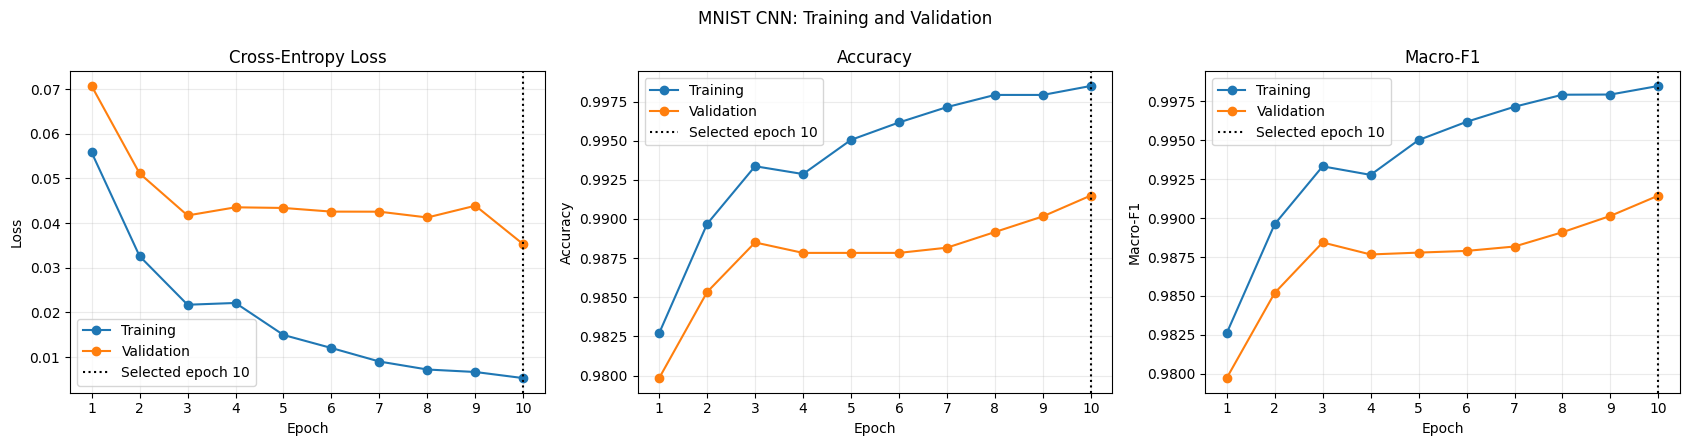

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

plot_settings = [
    ("loss", "Cross-Entropy Loss", "Loss"),
    ("accuracy", "Accuracy", "Accuracy"),
    ("macro_f1", "Macro-F1", "Macro-F1"),
]

for ax, (metric, title, ylabel) in zip(axes, plot_settings):
    ax.plot(
        cnn_history_df["epoch"],
        cnn_history_df[f"train_{metric}"],
        marker="o",
        label="Training",
    )
    ax.plot(
        cnn_history_df["epoch"],
        cnn_history_df[f"validation_{metric}"],
        marker="o",
        label="Validation",
    )
    ax.axvline(
        cnn_best_epoch,
        color="black",
        linestyle=":",
        label=f"Selected epoch {cnn_best_epoch}",
    )
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=ylabel,
        xticks=cnn_history_df["epoch"],
    )
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("MNIST CNN: Training and Validation")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "cnn_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

,model,split,loss,accuracy,macro_f1
0,CNN,train,0.005289,0.9985,0.998486
1,CNN,validation,0.035260,0.9915,0.991446


,precision,recall,f1-score,support
0,0.9916,0.9966,0.9941,592.0
1,0.9941,0.9970,0.9956,674.0
2,0.9867,0.9933,0.9900,596.0
3,0.9967,0.9869,0.9918,613.0
4,0.9881,0.9966,0.9923,584.0
5,0.9908,0.9945,0.9926,542.0
6,0.9983,0.9983,0.9983,592.0
7,0.9920,0.9904,0.9912,627.0
8,0.9880,0.9829,0.9854,585.0
9,0.9881,0.9782,0.9831,595.0


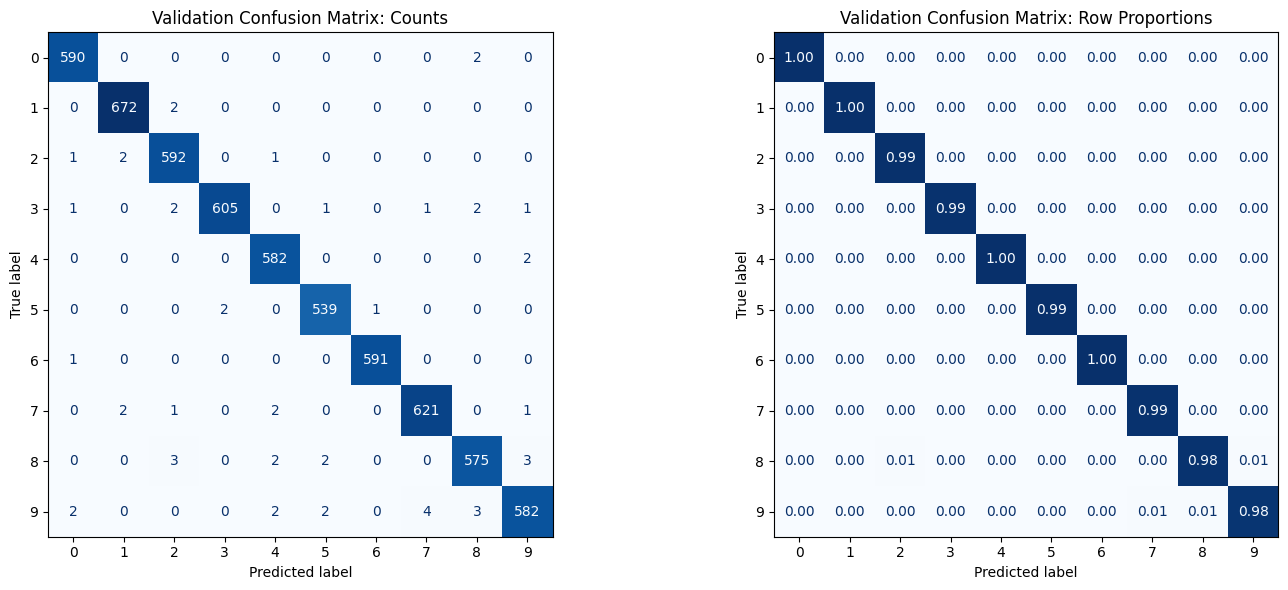

Validation errors: 51
PASS: restored checkpoint matches selected-epoch metrics.
Test set remains unevaluated.


In [14]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

cnn_train_metrics, _, _ = evaluate_cnn(cnn_model, train_eval_loader)
cnn_validation_metrics, cnn_val_true, cnn_val_pred = evaluate_cnn(
    cnn_model, validation_loader
)

selected_record = cnn_history_df.loc[
    cnn_history_df["epoch"] == cnn_best_epoch
].iloc[0]

for split, metrics in [
    ("train", cnn_train_metrics),
    ("validation", cnn_validation_metrics),
]:
    for metric, value in metrics.items():
        assert np.isclose(
            value,
            selected_record[f"{split}_{metric}"],
            rtol=1e-5,
            atol=1e-7,
        ), f"Checkpoint mismatch: {split} {metric}"

cnn_metrics_df = pd.DataFrame([
    {"model": "CNN", "split": "train", **cnn_train_metrics},
    {"model": "CNN", "split": "validation", **cnn_validation_metrics},
])
display(cnn_metrics_df.round(6))
cnn_metrics_df.to_csv(RESULTS_DIR / "cnn_metrics.csv", index=False)

cnn_report = classification_report(
    cnn_val_true,
    cnn_val_pred,
    labels=np.arange(10),
    target_names=[str(digit) for digit in range(10)],
    output_dict=True,
    zero_division=0,
)

cnn_class_report = pd.DataFrame(cnn_report).T.loc[
    [str(digit) for digit in range(10)] + ["macro avg", "weighted avg"]
]
display(cnn_class_report.round(4))
cnn_class_report.to_csv(
    RESULTS_DIR / "cnn_validation_classification_report.csv",
    index_label="class_or_summary",
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, normalization, title, value_format in [
    (axes[0], None, "Validation Confusion Matrix: Counts", "d"),
    (axes[1], "true", "Validation Confusion Matrix: Row Proportions", ".2f"),
]:
    ConfusionMatrixDisplay.from_predictions(
        cnn_val_true,
        cnn_val_pred,
        labels=np.arange(10),
        normalize=normalization,
        cmap="Blues",
        values_format=value_format,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)

fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "cnn_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Validation errors:", int((cnn_val_true != cnn_val_pred).sum()))
print("PASS: restored checkpoint matches selected-epoch metrics.")
print("Test set remains unevaluated.")

In [15]:
assert np.array_equal(
    cnn_val_true,
    official_train_labels[validation_indices],
)

cnn_predictions_df = pd.DataFrame({
    "source_index": validation_indices,
    "true_digit": cnn_val_true,
    "predicted_digit": cnn_val_pred,
})
cnn_predictions_df["correct"] = (
    cnn_predictions_df["true_digit"]
    == cnn_predictions_df["predicted_digit"]
)

saved_metrics = classification_metrics(
    cnn_predictions_df["true_digit"],
    cnn_predictions_df["predicted_digit"],
)

for metric, value in saved_metrics.items():
    assert np.isclose(value, cnn_validation_metrics[metric])

cnn_predictions_df.to_csv(
    RESULTS_DIR / "cnn_validation_predictions.csv",
    index=False,
)

cnn_experiment_config = {
    **cnn_config,
    "selected_epoch": int(cnn_best_epoch),
    "epochs_run": len(cnn_history_df),
    "trainable_parameters": sum(
        p.numel() for p in cnn_model.parameters() if p.requires_grad
    ),
    "training_seconds": float(cnn_training_seconds),
    "timing_scope": (
        "Training plus full training/validation evaluation each epoch; "
        "excludes downloads and final file exports"
    ),
    "gpus_used": 1,
    "gpu": torch.cuda.get_device_name(device),
    "environment": environment,
    "split_sha256": split_hash,
    "source_sha256": source_hashes,
    "training_metrics": cnn_train_metrics,
    "validation_metrics": cnn_validation_metrics,
    "checkpoint": "cnn_best.pt",
    "test_evaluated": False,
}

config_path = RESULTS_DIR / "cnn_config.json"
config_path.write_text(
    json.dumps(cnn_experiment_config, indent=2),
    encoding="utf-8",
)

print("Saved configuration:", config_path)
print("Saved validation predictions:", len(cnn_predictions_df))
print("Validation errors:", int((~cnn_predictions_df["correct"]).sum()))
print("Selected checkpoint:", checkpoint_dir / "cnn_best.pt")
print("PASS: predictions match the reported validation metrics.")
print("Test set remains unevaluated.")

Saved configuration: /kaggle/working/results/cnn_config.json
Saved validation predictions: 6000
Validation errors: 51
Selected checkpoint: /kaggle/working/checkpoints/cnn_best.pt
PASS: predictions match the reported validation metrics.
Test set remains unevaluated.


### CNN results and interpretation
